# DSCI 552 — Homework 7
Matthew Hall

## 1. Multi-class and Multi-label Classification Using SVMs
### (a) Load the data and create the training/test split

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

df = pd.read_csv("/content/Frogs_MFCCs.csv")

# Use only the MFCC measurements as predictors.
label_columns = ["Family", "Genus", "Species"]
feature_columns = [col for col in df.columns if col.startswith("MFCC")]

X = df[feature_columns]
y = df[label_columns]

# Randomly assign 70% of observations to training and 30% to testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("\nMissing values:", df.isna().sum().sum())

display(df.head())
display(
    pd.DataFrame({
        "Number of classes": y.nunique(),
        "Training classes": y_train.nunique(),
        "Testing classes": y_test.nunique()
    })
)

Dataset shape: (7195, 26)
Number of features: 22
Training observations: 5036
Testing observations: 2159

Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


,Number of classes,Training classes,Testing classes
Family,4,4,4
Genus,8,8,8
Species,10,10,10


### (b)(i) Evaluation metrics

Exact match accuracy measures the proportion of observations for which all three
labels—Family, Genus, and Species—are predicted correctly. A prediction receives
no credit under this metric if any of its labels are incorrect.

Hamming loss measures the fraction of individual label predictions that are
incorrect. Here, each observation has three label positions, so we divide the
total number of incorrect predictions by three times the number of observations.
Hamming distance counts the incorrect labels per observation, ranging from 0 to 3.

We report label-wise accuracy as 1 − Hamming loss. The term "Hamming score" is
also used for sample-wise Jaccard similarity, so we report that separately.
Jaccard similarity divides the number of correctly predicted labels by the
size of the union of the true and predicted label sets, treating each label
as a (target, class) pair.

Higher exact match accuracy, label-wise accuracy, and Jaccard score are better.
Lower Hamming loss and Hamming distance are better.

In [ ]:
def evaluate_multilabel(y_true, y_pred):
    """Evaluate predictions across Family, Genus, and Species."""
    true = np.asarray(y_true)
    pred = np.asarray(y_pred)

    correct = (true == pred)
    matches_per_row = correct.sum(axis=1)
    n_labels = true.shape[1]

    return {
        "Exact match accuracy": correct.all(axis=1).mean(),
        "Hamming distance": (~correct).sum(axis=1).mean(),
        "Hamming loss": (~correct).mean(),
        "Label-wise accuracy": correct.mean(),
        "Hamming score (Jaccard)": np.mean(
            matches_per_row / (2 * n_labels - matches_per_row)
        )
    }


# Sanity checks: perfect predictions and one incorrect label.
example_true = np.array([
    ["Family_A", "Genus_A", "Species_A"],
    ["Family_B", "Genus_B", "Species_B"]
])

example_pred = example_true.copy()
example_pred[0, 2] = "Species_C"

display(pd.DataFrame({
    "Perfect predictions": evaluate_multilabel(example_true, example_true),
    "One incorrect label": evaluate_multilabel(example_true, example_pred)
}))

,Perfect predictions,One incorrect label
Exact match accuracy,1.0,0.500000
Hamming distance,0.0,0.500000
Hamming loss,0.0,0.166667
Label-wise accuracy,1.0,0.833333
Hamming score (Jaccard),1.0,0.750000


### (b)(ii) Gaussian-kernel SVMs

I train a separate classifier for Family, Genus, and Species, using
one-versus-rest classification within each target. I use the raw MFCC
features, which are already normalized.

For each target, I select C and gamma using shuffled, stratified 10-fold
cross-validation on the training set, with accuracy as the selection metric.
C controls the penalty for classification errors. Gamma controls the width
of the Gaussian kernel, with gamma = 1 / (2 sigma²).

The test set is reserved for evaluating the selected models.

In [ ]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_rows = []

for label in label_columns:
    print(f"\nTuning Gaussian SVM for {label}...", flush=True)

    # Include the wider penalty range checked for Family.
    C_grid = (
        [0.1, 1, 10, 100, 1000, 10000]
        if label == "Family"
        else [0.1, 1, 10, 100]
    )

    search = GridSearchCV(
        estimator=OneVsRestClassifier(
            SVC(kernel="rbf", cache_size=200),
            n_jobs=1
        ),
        param_grid={
            "estimator__C": C_grid,
            "estimator__gamma": [0.01, 0.1, 1, 10]
        },
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        pre_dispatch="n_jobs",
        refit=True,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])

    rbf_models[label] = search
    rbf_predictions[label] = search.predict(X_test)

    rbf_rows.append({
        "Target": label,
        "Best C": search.best_params_["estimator__C"],
        "Best gamma": search.best_params_["estimator__gamma"],
        "Best CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(
            y_test[label], rbf_predictions[label]
        )
    })

    print(
        f"Best parameters: {search.best_params_}\n"
        f"Best CV accuracy: {search.best_score_:.6f}",
        flush=True
    )

rbf_results = pd.DataFrame(rbf_rows).set_index("Target")

# Preserve other model results if this cell is run again.
if "model_results" not in globals():
    model_results = {}

model_results["Gaussian SVM (raw)"] = evaluate_multilabel(
    y_test[label_columns],
    rbf_predictions[label_columns]
)

display(rbf_results)
display(pd.DataFrame(model_results).T)


Tuning Gaussian SVM for Family...
Fitting 10 folds for each of 24 candidates, totalling 240 fits
Best parameters: {'estimator__C': 1000, 'estimator__gamma': 1}
Best CV accuracy: 0.991659

Tuning Gaussian SVM for Genus...
Fitting 10 folds for each of 16 candidates, totalling 160 fits
Best parameters: {'estimator__C': 10, 'estimator__gamma': 1}
Best CV accuracy: 0.991064

Tuning Gaussian SVM for Species...
Fitting 10 folds for each of 16 candidates, totalling 160 fits
Best parameters: {'estimator__C': 10, 'estimator__gamma': 1}
Best CV accuracy: 0.990074


,Best C,Best gamma,Best CV accuracy,Test accuracy
Target,,,,
Family,1000,1,0.991659,0.995831
Genus,10,1,0.991064,0.990273
Species,10,1,0.990074,0.990736


,Exact match accuracy,Hamming distance,Hamming loss,Label-wise accuracy,Hamming score (Jaccard)
Gaussian SVM (raw),0.987494,0.023159,0.00772,0.99228,0.990829


### (b)(iii) L1-penalized SVMs

I train a separate L1-penalized linear SVM for each target using
one-versus-rest classification. I standardize the features inside a
pipeline so that each cross-validation fold uses scaling parameters
estimated only from its training portion.

For each target, I select C using stratified 10-fold cross-validation
with accuracy as the selection metric. I then evaluate the selected
models on the test set using the same metrics as the Gaussian SVMs.

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_rows = []

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

for label in label_columns:
    print(f"\nTuning L1 SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"svm__C": C_values},
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        pre_dispatch="n_jobs",
        refit=True,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])

    l1_models[label] = search
    l1_predictions[label] = search.predict(X_test)

    best_C = search.best_params_["svm__C"]

    l1_rows.append({
        "Target": label,
        "Best C": best_C,
        "Best CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(
            y_test[label], l1_predictions[label]
        )
    })

    print(
        f"Best C: {best_C}\n"
        f"Best CV accuracy: {search.best_score_:.6f}",
        flush=True
    )

    if best_C in (min(C_values), max(C_values)):
        print("Best C is at the search boundary.")

l1_results = pd.DataFrame(l1_rows).set_index("Target")

if "model_results" not in globals():
    model_results = {}

model_results["L1 SVM (standardized)"] = evaluate_multilabel(
    y_test[label_columns],
    l1_predictions[label_columns]
)

display(l1_results)
display(pd.DataFrame(model_results).T)


Tuning L1 SVM for Family...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 10
Best CV accuracy: 0.941223

Tuning L1 SVM for Genus...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 100
Best CV accuracy: 0.951551
Best C is at the search boundary.

Tuning L1 SVM for Species...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 10
Best CV accuracy: 0.960682


,Best C,Best CV accuracy,Test accuracy
Target,,,
Family,10,0.941223,0.928208
Genus,100,0.951551,0.941640
Species,10,0.960682,0.959240


,Exact match accuracy,Hamming distance,Hamming loss,Label-wise accuracy,Hamming score (Jaccard)
Gaussian SVM (raw),0.987494,0.023159,0.007720,0.992280,0.990829
L1 SVM (standardized),0.912459,0.170912,0.056971,0.943029,0.934182


### (b)(iv) L1-penalized SVMs with class balancing

I address class imbalance using balanced class weights. Each class receives
a weight inversely proportional to its frequency in the training data, so
errors on minority classes receive larger penalties.

I use the same standardized L1-penalized linear SVM approach and select C
using stratified 10-fold cross-validation. Scaling and class weights are
learned from each fold's training portion.

I compare the models using the previous metrics and macro F1, which gives
each class equal weight and helps assess performance on minority classes.

In [19]:
from sklearn.metrics import f1_score

balanced_models = {}
balanced_predictions = pd.DataFrame(index=y_test.index)
balanced_rows = []

for label in label_columns:
    print(f"\nTuning balanced L1 SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            class_weight="balanced",
            max_iter=100000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"svm__C": C_values},
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        pre_dispatch="n_jobs",
        refit=True,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])

    balanced_models[label] = search
    balanced_predictions[label] = search.predict(X_test)

    best_C = search.best_params_["svm__C"]

    balanced_rows.append({
        "Target": label,
        "Best C": best_C,
        "Best CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(
            y_test[label], balanced_predictions[label]
        )
    })

    print(
        f"Best C: {best_C}\n"
        f"Best CV accuracy: {search.best_score_:.6f}",
        flush=True
    )

    if best_C in (min(C_values), max(C_values)):
        print("Best C is at the search boundary.")

balanced_results = pd.DataFrame(balanced_rows).set_index("Target")

model_results["L1 SVM (balanced)"] = evaluate_multilabel(
    y_test[label_columns],
    balanced_predictions[label_columns]
)

display(balanced_results)
display(pd.DataFrame(model_results).T)

# Give each class equal importance when comparing F1 scores.
prediction_sets = {
    "Gaussian SVM (raw)": rbf_predictions,
    "L1 SVM (standardized)": l1_predictions,
    "L1 SVM (balanced)": balanced_predictions
}

macro_f1_results = pd.DataFrame({
    name: {
        label: f1_score(
            y_test[label],
            predictions[label],
            average="macro",
            zero_division=0
        )
        for label in label_columns
    }
    for name, predictions in prediction_sets.items()
})

macro_f1_results.index.name = "Target"
print("\nTest macro F1 by target:")
display(macro_f1_results)


Tuning balanced L1 SVM for Family...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 100
Best CV accuracy: 0.934473
Best C is at the search boundary.

Tuning balanced L1 SVM for Genus...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 10
Best CV accuracy: 0.943017

Tuning balanced L1 SVM for Species...
Fitting 10 folds for each of 6 candidates, totalling 60 fits
Best C: 10
Best CV accuracy: 0.959892


,Best C,Best CV accuracy,Test accuracy
Target,,,
Family,100,0.934473,0.921723
Genus,10,0.943017,0.940713
Species,10,0.959892,0.959704


,Exact match accuracy,Hamming distance,Hamming loss,Label-wise accuracy,Hamming score (Jaccard)
Gaussian SVM (raw),0.987494,0.023159,0.007720,0.992280,0.990829
L1 SVM (standardized),0.912459,0.170912,0.056971,0.943029,0.934182
L1 SVM (balanced),0.906901,0.177860,0.059287,0.940713,0.930848



Test macro F1 by target:


,Gaussian SVM (raw),L1 SVM (standardized),L1 SVM (balanced)
Target,,,
Family,0.987471,0.682802,0.815708
Genus,0.972483,0.809147,0.859585
Species,0.978226,0.906036,0.900937


### Comparison and conclusions

The Gaussian SVM performed best, with an exact match accuracy of 98.75%
and a Hamming loss of 0.00772. The standardized L1 linear SVM achieved
91.25% exact match accuracy and a Hamming loss of 0.05697. These results
suggest that nonlinear decision boundaries are useful for this dataset.

Balancing class weights reduced exact match accuracy slightly, from 91.25%
to 90.69%. However, Family macro F1 increased from 0.683 to 0.816, and
Genus macro F1 increased from 0.809 to 0.860. This indicates better
performance when classes receive equal importance, despite the decrease
in overall accuracy. Species macro F1 decreased slightly, from 0.906
to 0.901, so balancing did not improve every target.

Overall, the Gaussian SVM achieved the strongest results, including the
highest macro F1 for all three targets. The reported parameters are the
best within the searched grids. The unbalanced Genus and balanced Family
L1 models selected C = 100, the largest value tested, so their searches
do not establish whether larger values would improve cross-validation
accuracy.

## 2. K-means clustering with 50 Monte Carlo runs

### (a) Automatically selecting k

I use all 7,195 observations and the 22 raw, normalized MFCC features,
excluding RecordID and the target labels. No train/test split is used.

In each of 50 runs, I fit k-means for k = 2, ..., 50 and select the k
with the highest Calinski–Harabasz score. This score is undefined for
k = 1, so that candidate is excluded.

Each run uses a different reproducible random seed. I use k-means++
initialization with one initialization per candidate per run, allowing
the Monte Carlo experiment to capture variation from initialization.

### (b) Assigning majority labels

For each selected clustering, I independently find the most frequent
Family, Genus, and Species in each cluster. Every observation in that
cluster receives the resulting majority-label triplet. Ties are resolved
by taking the first mode in sorted order. True labels are used only
after clustering, for majority assignment and evaluation.

### (c) Evaluating the cluster labels

For each run, I calculate average Hamming distance, Hamming loss,
label-wise accuracy, and sample-wise Jaccard score using the definitions
from Question 1. I report the mean and sample standard deviation across
the 50 runs.

In [20]:
import time
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from threadpoolctl import threadpool_limits

X_cluster = X.to_numpy(dtype=float)
y_cluster = y[label_columns].reset_index(drop=True)

clustering_rows = []
ch_rows = []
first_run_majorities = None

start_time = time.perf_counter()

# Limit numerical-library threading to avoid unnecessary overhead.
with threadpool_limits(limits=1):
    for run in range(50):
        seed = RANDOM_STATE + run
        best_score = -np.inf
        best_k = None
        best_clusters = None

        for k in range(2, 51):
            model = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=1,
                max_iter=300,
                random_state=seed,
                algorithm="lloyd"
            )

            clusters = model.fit_predict(X_cluster)
            score = calinski_harabasz_score(X_cluster, clusters)

            ch_rows.append({
                "Run": run + 1,
                "k": k,
                "CH score": score
            })

            if score > best_score:
                best_score = score
                best_k = k
                best_clusters = clusters.copy()

        # Independently determine each target's majority in each cluster.
        labeled_clusters = y_cluster.copy()
        labeled_clusters["Cluster"] = best_clusters

        majorities = (
            labeled_clusters
            .groupby("Cluster")[label_columns]
            .agg(lambda column: column.mode().iloc[0])
        )

        # Reconstruct predictions in the original observation order.
        predictions = majorities.loc[best_clusters].to_numpy()

        metrics = evaluate_multilabel(
            y_cluster.to_numpy(),
            predictions
        )

        clustering_rows.append({
            "Run": run + 1,
            "Seed": seed,
            "Selected k": best_k,
            "CH score": best_score,
            **metrics
        })

        # Retain an example majority-label table for the write-up.
        if run == 0:
            first_run_majorities = majorities.copy()
            first_run_majorities["Cluster size"] = (
                labeled_clusters.groupby("Cluster").size()
            )

        elapsed_minutes = (time.perf_counter() - start_time) / 60

        print(
            f"Run {run + 1:02d}/50 | k={best_k} | "
            f"Hamming distance={metrics['Hamming distance']:.4f} | "
            f"Elapsed={elapsed_minutes:.1f} min",
            flush=True
        )

clustering_results = pd.DataFrame(clustering_rows)
ch_results = pd.DataFrame(ch_rows)

metric_columns = [
    "Hamming distance",
    "Hamming loss",
    "Label-wise accuracy",
    "Hamming score (Jaccard)",
    "Exact match accuracy"
]

clustering_summary = (
    clustering_results[metric_columns]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean",
        "std": "Sample standard deviation"
    })
)

print("\nResults across 50 runs:")
display(clustering_summary)

print("\nFrequency of selected k:")
display(
    clustering_results["Selected k"]
    .value_counts()
    .sort_index()
    .rename_axis("k")
    .to_frame("Number of runs")
)

print("\nExample majority-label assignments from run 1:")
display(first_run_majorities)

Run 01/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.1 min
Run 02/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.2 min
Run 03/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.2 min
Run 04/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.3 min
Run 05/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.3 min
Run 06/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.4 min
Run 07/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.4 min
Run 08/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.5 min
Run 09/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.5 min
Run 10/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.6 min
Run 11/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.7 min
Run 12/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.7 min
Run 13/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.8 min
Run 14/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.8 min
Run 15/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.9 min
Run 16/50 | k=2 | Hamming distance=0.8956 | Elapsed=0.9 min
Run 17/50 | k=2 | Hamming distance=0.895

,Mean,Sample standard deviation
Hamming distance,0.895622,1.121495e-16
Hamming loss,0.298541,1.682242e-16
Label-wise accuracy,0.701459,2.242989e-16
Hamming score (Jaccard),0.681890,3.364484e-16
Exact match accuracy,0.636136,4.485978e-16



Frequency of selected k:


,Number of runs
k,
2,50



Example majority-label assignments from run 1:


,Family,Genus,Species,Cluster size
Cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598
1,Hylidae,Hypsiboas,HypsiboasCordobae,3597


### Clustering results and interpretation

The Calinski–Harabasz criterion selected k = 2 in all 50 runs. The mean
Hamming distance was 0.895622 out of three labels per observation,
corresponding to a Hamming loss of 0.298541 and label-wise accuracy
of 70.15%. Exact match accuracy was 63.61%, and the mean Jaccard
score was 0.681890.

All 50 runs produced the same evaluation scores. Their standard
deviations were effectively zero; the tiny reported values reflect
floating-point rounding.

In the first run, the clusters contained 3,598 and 3,597 observations.
Their majority-label triplets were
(Leptodactylidae, Adenomera, AdenomeraHylaedactylus) and
(Hylidae, Hypsiboas, HypsiboasCordobae).

The CH criterion selected broad groups in the feature space, but these
two groups did not capture the full variety of families, genera, and
species. The majority-label approach therefore made substantial errors.
CH selects clusters based on feature separation rather than agreement
with the biological labels.

These clustering scores describe majority-label agreement on the full
dataset. They are not directly comparable to the supervised models'
held-out test scores.

## 3. ISLR 12.6.2

### (a) Complete linkage

Complete linkage defines the distance between two clusters as the
largest dissimilarity between their observations.

First, observations 1 and 2 merge at height 0.30. Their distances to
observations 3 and 4 are:

- d({1,2}, {3}) = max(0.40, 0.50) = 0.50
- d({1,2}, {4}) = max(0.70, 0.80) = 0.80

Since d(3,4) = 0.45 is the smallest remaining distance, observations
3 and 4 merge at height 0.45.

Finally, {1,2} and {3,4} merge at height
max(0.40, 0.70, 0.50, 0.80) = 0.80.

### (b) Single linkage

Single linkage defines the distance between two clusters as the
smallest dissimilarity between their observations.

First, observations 1 and 2 merge at height 0.30. Then observation 3
joins them at height min(0.40, 0.50) = 0.40.

Finally, observation 4 joins {1,2,3} at height
min(0.70, 0.80, 0.45) = 0.45.

### (c) Two clusters under complete linkage

The clusters are {1,2} and {3,4}. A horizontal cut at height 0.60
produces these two clusters.

### (d) Two clusters under single linkage

The clusters are {1,2,3} and {4}. A horizontal cut at height 0.425
produces these two clusters.

### (e) An equivalent complete-linkage dendrogram

Swapping leaves 1 and 2 gives the leaf order 2,1,3,4 without changing
any cluster memberships or merge heights. Observations 1 and 2 still
merge at 0.30, observations 3 and 4 still merge at 0.45, and the two
clusters still merge at 0.80.

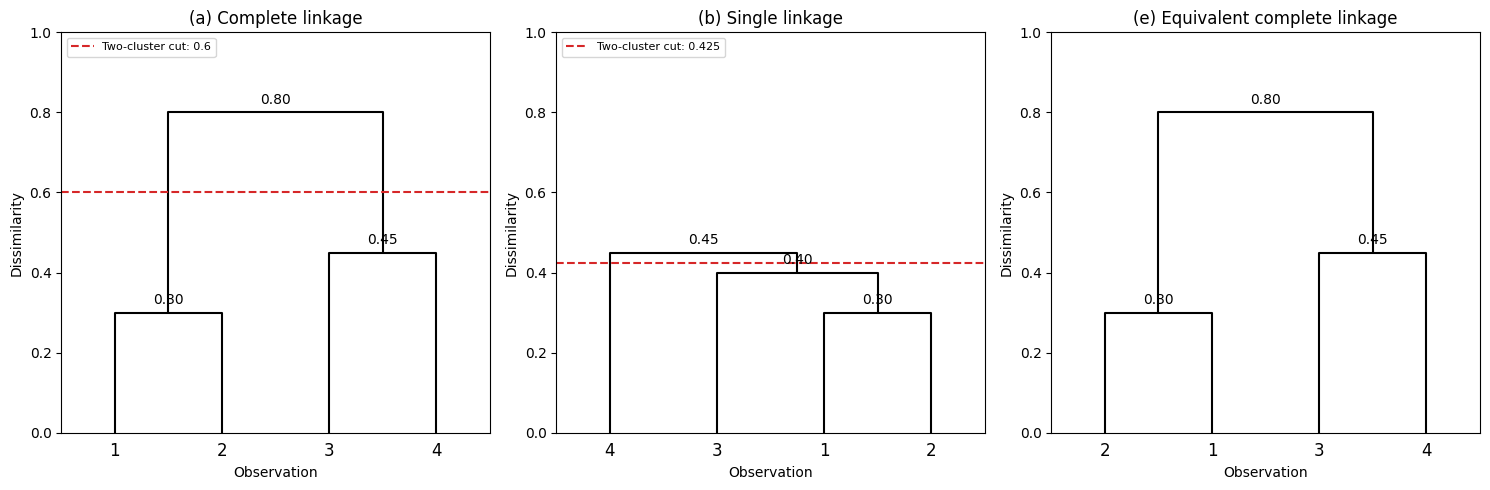

In [21]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# Diagonal entries are zero; the matrix is symmetric.
dissimilarities = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00]
])

# Pass pairwise dissimilarities, rather than treating matrix rows as features.
condensed = squareform(dissimilarities)

Z_complete = linkage(condensed, method="complete")
Z_single = linkage(condensed, method="single")

# Swap the children of the first merge to reposition leaves 1 and 2.
Z_equivalent = Z_complete.copy()
Z_equivalent[0, [0, 1]] = Z_equivalent[0, [1, 0]]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

plots = [
    (Z_complete, "(a) Complete linkage", 0.60),
    (Z_single, "(b) Single linkage", 0.425),
    (Z_equivalent, "(e) Equivalent complete linkage", None)
]

for ax, (Z, title, cut_height) in zip(axes, plots):
    tree = dendrogram(
        Z,
        labels=["1", "2", "3", "4"],
        ax=ax,
        color_threshold=0,
        above_threshold_color="black"
    )

    # Label each horizontal merge segment with its height.
    for xs, ys in zip(tree["icoord"], tree["dcoord"]):
        ax.annotate(
            f"{ys[1]:.2f}",
            xy=((xs[1] + xs[2]) / 2, ys[1]),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

    if cut_height is not None:
        ax.axhline(
            cut_height,
            color="tab:red",
            linestyle="--",
            label=f"Two-cluster cut: {cut_height:g}"
        )
        ax.legend(loc="upper left", fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Dissimilarity")
    ax.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()